In [1]:
%matplotlib inline

# Imports

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sqlite3
import sys
from io import StringIO
from scipy.stats import shapiro, f_oneway, kruskal, mannwhitneyu
import scikit_posthocs as sp
from itertools import combinations
from string import ascii_lowercase

# Config

In [32]:
data_dir = Path("../data/260801_135508/")
pd.options.display.max_rows = 100

# Data

## Frame Level Data

In [4]:
type_dict = {"shader_pipeline": str, "ninstances": int, "frame_number": int}
raw_data_dfs = []
for shaderpipeline_dir in data_dir.iterdir():
    shaderpipeline_str = str(shaderpipeline_dir).split("/")[-1]
    print(shaderpipeline_str)
    for ninstance_dir in shaderpipeline_dir.iterdir():
        ninstance_str = str(ninstance_dir).split("/")[-1][1:]
        # print(ninstance_str)
        gpu_frametime_filepath = ninstance_dir / "BASE/FRAME.xls"
        app_data_filepath = ninstance_dir / "app_metrics.csv"
        app_data_with_gpu_filepath = ninstance_dir / "app_metrics_with_gpu.csv"
        
        gpu_frametime_df = pd.read_csv(gpu_frametime_filepath, sep="\t", header=None).T.drop(0).rename(columns={0: "gpu_frame_time_ms"})
        gpu_frametime_df["shader_pipeline"] = shaderpipeline_str
        gpu_frametime_df["ninstances"] = int(ninstance_str)
        gpu_frametime_df = (
            gpu_frametime_df
                .astype({"gpu_frame_time_ms": float, "ninstances": int})
                .reset_index(names=["frame_number"])
                
        )
        gpu_frametime_df["frame_number"] -= 1
        gpu_frametime_df = (
            gpu_frametime_df
                .astype(type_dict)
                .set_index(["shader_pipeline", "ninstances", "frame_number"])
        )
            

        # csv data malformed with trailing , in data and not header column
        with open(app_data_filepath) as f:
            app_data_as_string = "".join(
                line.rstrip("\n").rstrip(",") + "\n"
                for line in f
            )
        app_data_df = (
            pd.read_csv(StringIO(app_data_as_string))
                .dropna(how="any")
                .astype(type_dict)
                .set_index(["shader_pipeline", "ninstances", "frame_number"])
        )

        app_data_with_gpu_df = (
            pd.read_csv(app_data_with_gpu_filepath)
                .dropna(how="any")
                .drop(columns=["frame_time"])
                .astype(type_dict)
                .set_index(["shader_pipeline", "ninstances", "frame_number"])
        )

        raw_data_df = (
            pd.concat([gpu_frametime_df, app_data_df, app_data_with_gpu_df], axis=1, join="inner")
        )
        raw_data_dfs.append(raw_data_df)
        
data_df = (
    pd.concat(raw_data_dfs)
        .round(3)
        .reset_index()
)

asteroidInstancedVertex
asteroidInstancedVertexCompute
asteroidMesh
asteroidMeshCompute
asteroidMeshDXExample


In [5]:
data_df.head()

,shader_pipeline,ninstances,frame_number,gpu_frame_time_ms,frame_time,vram_used
0,asteroidInstancedVertex,10,0,0.710,2949.810,2.236
1,asteroidInstancedVertex,10,1,0.766,6.319,2.190
2,asteroidInstancedVertex,10,2,0.369,0.715,2.190
3,asteroidInstancedVertex,10,3,0.295,0.720,2.190
4,asteroidInstancedVertex,10,4,0.785,0.757,2.190


In [6]:
# instanced vertex missing an ninstances as didn't run
data_df.loc[len(data_df)] = ["asteroidInstancedVertex", 10_000_000, 0, np.nan, np.nan, np.nan]

In [7]:
data_df["shader_pipeline"] = data_df["shader_pipeline"].apply(lambda s: s.split("asteroid")[1])

## Vulkan Command Data

In [49]:
def format_gpu_time(val):
    if isinstance(val, str):
        val = val[:-2]
        if val.startswith("<"):
            val = 0.0
    return val

In [50]:
raw_data_dfs = []
for shaderpipeline_dir in data_dir.iterdir():
    shaderpipeline_str = str(shaderpipeline_dir).split("/")[-1]
    print(shaderpipeline_str)
    for ninstance_dir in shaderpipeline_dir.iterdir():
        ninstance_str = str(ninstance_dir).split("/")[-1][1:]
        vulkan_command_path = ninstance_dir / "EventList.csv"
        vulkan_command_df = pd.read_csv(vulkan_command_path)
        vulkan_command_df["shader_pipeline"] = shaderpipeline_str
        vulkan_command_df["ninstances"] = int(ninstance_str)

        vulkan_command_df = vulkan_command_df.rename(
            columns={
                "Frame": "frame_number",
                "Event": "event_number",
                "GPU Duration": "gpu_time_ms",
                "Description": "command"
            }
        )

        vulkan_command_df = vulkan_command_df.drop(["Separate Context Overlap"], axis=1)
        vulkan_command_df = vulkan_command_df.dropna(subset=["frame_number"])
        vulkan_command_df = vulkan_command_df[~vulkan_command_df["event_number"].str.contains("-")]\

        vulkan_command_df["gpu_time_ms"] = vulkan_command_df["gpu_time_ms"].apply(format_gpu_time)
        
        vulkan_command_df = vulkan_command_df.astype(
            {
                "frame_number": int,
                "event_number": int,
                "gpu_time_ms": float
            }
        )
        vulkan_command_df["event_number"] -= 1
        raw_data_dfs.append(vulkan_command_df)

        
gpu_command_df = pd.concat(raw_data_dfs, ignore_index=True)
gpu_command_df = gpu_command_df[
    [
        "shader_pipeline",
        "ninstances",
        "frame_number",
        "event_number",
        "command",
        "gpu_time_ms"
    ]
]
gpu_command_df["shader_pipeline"] = gpu_command_df["shader_pipeline"].apply(lambda s: s.split("asteroid")[1])
gpu_command_df.head()

asteroidInstancedVertex
asteroidInstancedVertexCompute
asteroidMesh
asteroidMeshCompute
asteroidMeshDXExample


,shader_pipeline,ninstances,frame_number,event_number,command,gpu_time_ms
0,InstancedVertex,10,0,0,vkCmdPipelineBarrier2(const VkDependencyInfo* ...,0.0
1,InstancedVertex,10,0,1,vkCmdPipelineBarrier2(const VkDependencyInfo* ...,0.0
2,InstancedVertex,10,0,2,vkCmdPipelineBarrier2(const VkDependencyInfo* ...,0.0
3,InstancedVertex,10,0,3,vkCmdCopyBuffer(VkBuffer srcBuffer = '0x000056...,0.0
4,InstancedVertex,10,0,4,vkCmdPipelineBarrier2(const VkDependencyInfo* ...,0.0


## SAVE

In [9]:
data_df.to_feather("../data/results/results.feather")
data_df.to_csv("../data/results/results.csv")

gpu_command_df.to_feather("../data/results/gpu_commands.feather")
gpu_command_df.to_csv("../data/results/gpu_commands.csv")

In [14]:
# aggregated_stats = (
#     data_df
#         .drop(columns=["frame_number"])
#         .groupby(["shader_pipeline", "ninstances"])
#         .agg(["mean", lambda s: s.std() * 2])\
#         .rename(columns={"<lambda_0>": "2_sigma"})
#         .round(2)
# )

# Analyse

In [46]:
index_cols = ["shader_pipeline", "ninstances", "frame_number"]
data_df.describe()

,ninstances,frame_number,gpu_frame_time_ms,frame_time,vram_used
count,2.040000e+03,2040.000000,2040.000000,2040.000000,2040.000000
mean,1.339869e+06,29.500000,78.820783,146.303132,4.349428
std,3.181660e+06,17.322348,241.261581,568.768069,2.949808
min,1.000000e+01,0.000000,0.110000,0.248000,2.190000
25%,1.000000e+02,14.750000,0.344000,0.344000,2.191000
50%,1.000000e+04,29.500000,0.711500,0.866500,2.207000
75%,1.000000e+06,44.250000,21.004250,22.046250,5.172000
max,1.000000e+07,59.000000,1452.110000,7614.460000,9.786000


## Frame times

### Outliers

In [8]:
index_cols = ["shader_pipeline", "ninstances", "frame_number"]
frame_df = data_df.set_index(index_cols)["frame_time"].reset_index()

In [9]:
frame_df.head()

,shader_pipeline,ninstances,frame_number,frame_time
0,InstancedVertex,10,0,2949.810
1,InstancedVertex,10,1,6.319
2,InstancedVertex,10,2,0.715
3,InstancedVertex,10,3,0.720
4,InstancedVertex,10,4,0.757


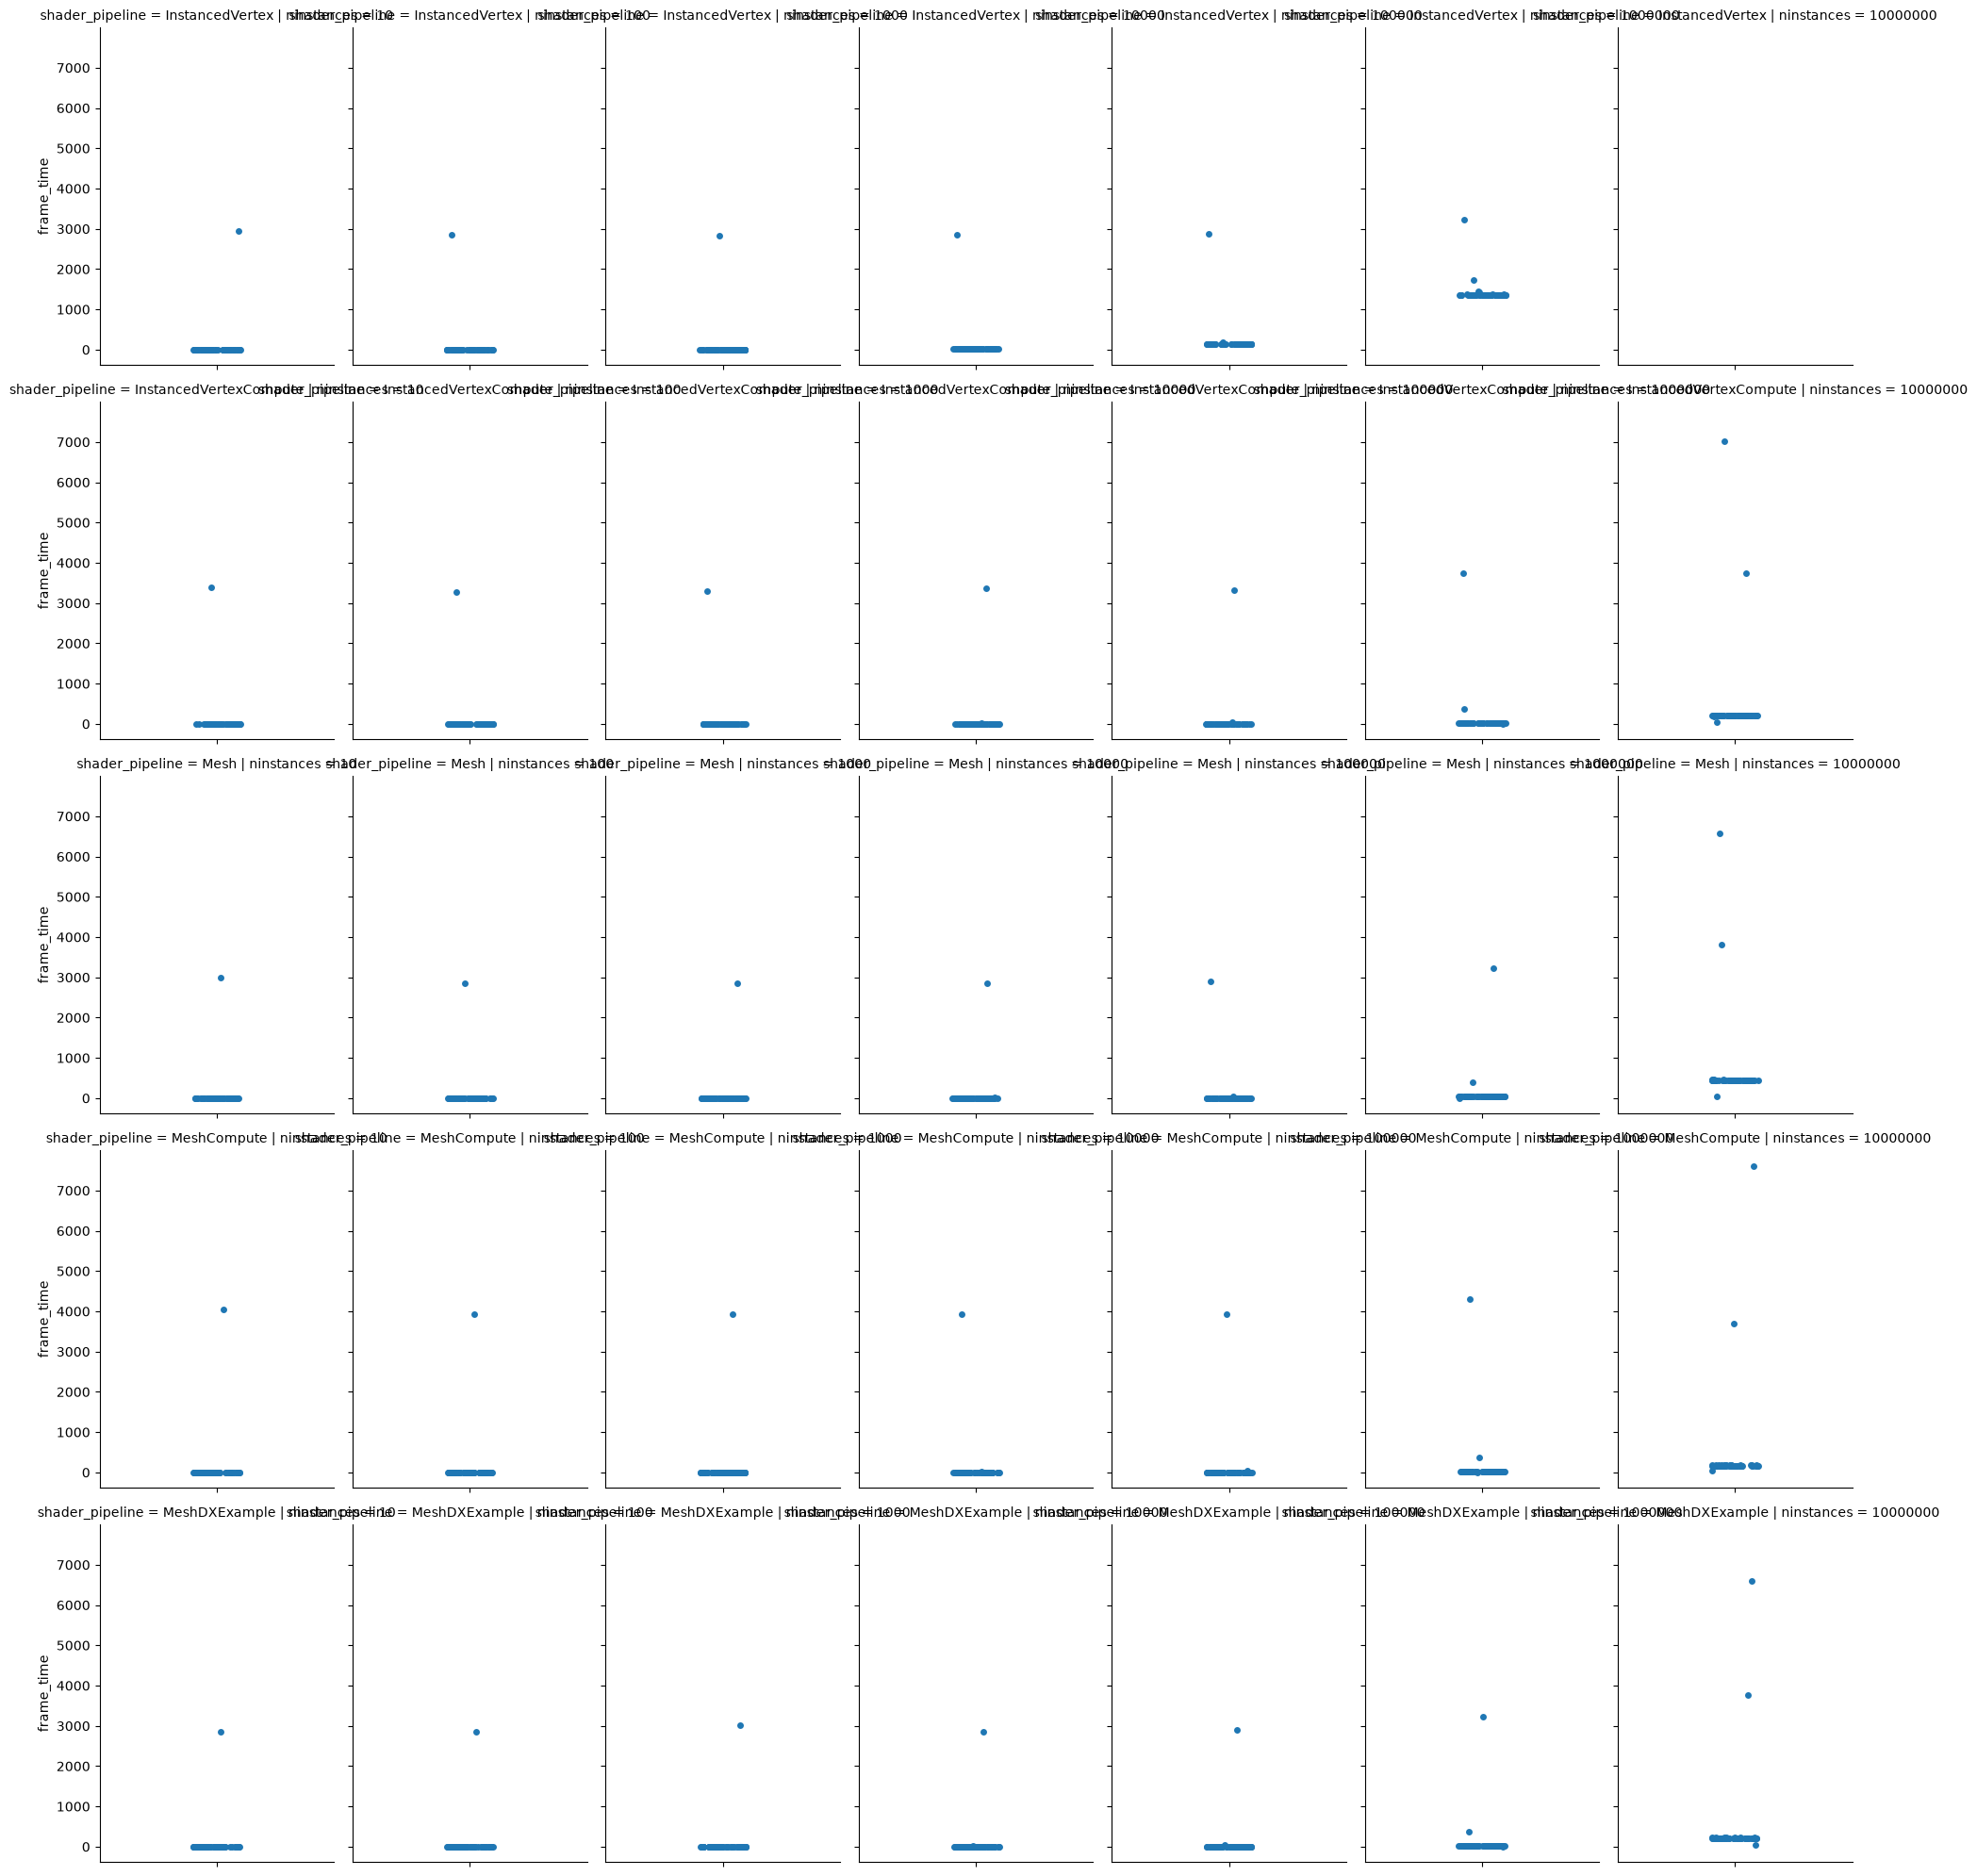

In [10]:
sns.catplot(
    data=frame_df, y="frame_time", col="ninstances", row="shader_pipeline",
    kind="strip", height=4, aspect=.7,
)

In [11]:
frame_df_proc = pd.concat(
    [
        frame_df.set_index(["shader_pipeline", "ninstances"]), 
        frame_df.groupby(["shader_pipeline", "ninstances"]).std().rename(columns={"frame_time": "std"}).drop("frame_number", axis=1),
        frame_df.groupby(["shader_pipeline", "ninstances"]).mean().rename(columns={"frame_time": "mean"}).drop("frame_number", axis=1)
    ], 
    axis=1
).reset_index()
frame_df_proc["z"] = (frame_df_proc["frame_time"] - frame_df_proc["mean"]) / frame_df_proc["std"]
frame_df_proc.head()

,shader_pipeline,ninstances,frame_number,frame_time,std,mean,z
0,InstancedVertex,10,0,2949.810,380.761516,49.60615,7.616851
1,InstancedVertex,10,1,6.319,380.761516,49.60615,-0.113686
2,InstancedVertex,10,2,0.715,380.761516,49.60615,-0.128404
3,InstancedVertex,10,3,0.720,380.761516,49.60615,-0.128390
4,InstancedVertex,10,4,0.757,380.761516,49.60615,-0.128293


<Axes: ylabel='z'>

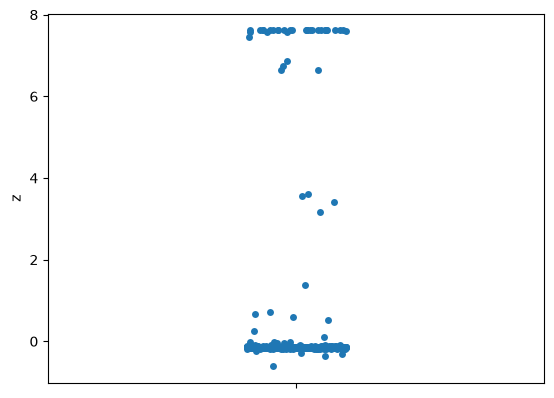

In [12]:
sns.stripplot(frame_df_proc, y="z")

<Axes: >

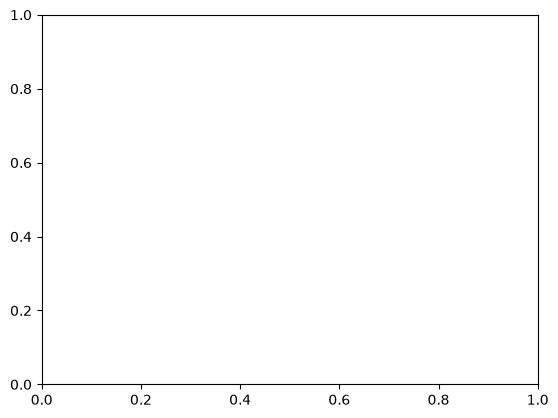

In [13]:
sns.stripplot(frame_df_proc[(frame_df_proc["shader_pipeline"]=="asteroidMesh") & (frame_df_proc["ninstances"] == 10_000_000)]["z"])

In [14]:
frame_df_proc[frame_df_proc["z"] < 0]

,shader_pipeline,ninstances,frame_number,frame_time,std,mean,z
1,InstancedVertex,10,1,6.319,380.761516,49.60615,-0.113686
2,InstancedVertex,10,2,0.715,380.761516,49.60615,-0.128404
3,InstancedVertex,10,3,0.720,380.761516,49.60615,-0.128390
4,InstancedVertex,10,4,0.757,380.761516,49.60615,-0.128293
5,InstancedVertex,10,5,0.378,380.761516,49.60615,-0.129289
...,...,...,...,...,...,...,...
2035,MeshDXExample,10,55,0.296,367.290217,47.85565,-0.129488
2036,MeshDXExample,10,56,0.305,367.290217,47.85565,-0.129463
2037,MeshDXExample,10,57,0.272,367.290217,47.85565,-0.129553
2038,MeshDXExample,10,58,0.293,367.290217,47.85565,-0.129496


<Axes: ylabel='frame_number'>

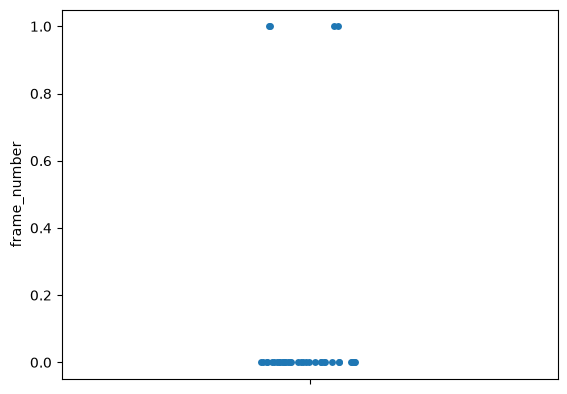

In [15]:
sns.stripplot(frame_df_proc[frame_df_proc["z"].abs() > 2], y="frame_number")

The outliers (abs(z) > 2) are always on the first frame or two. To be consistent I'll just remove the first two frames from the data.

In [16]:
frame_df_filtered = frame_df[frame_df["frame_number"] > 1]

<Axes: >

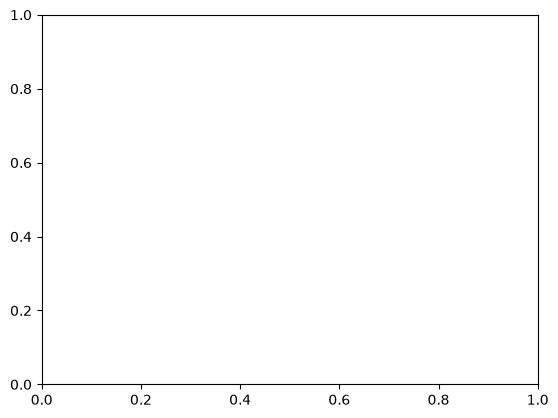

In [17]:
sns.stripplot(frame_df_filtered[(frame_df_filtered["shader_pipeline"]=="asteroidMesh") & (frame_df_filtered["ninstances"] == 10_000_000)]["frame_time"])

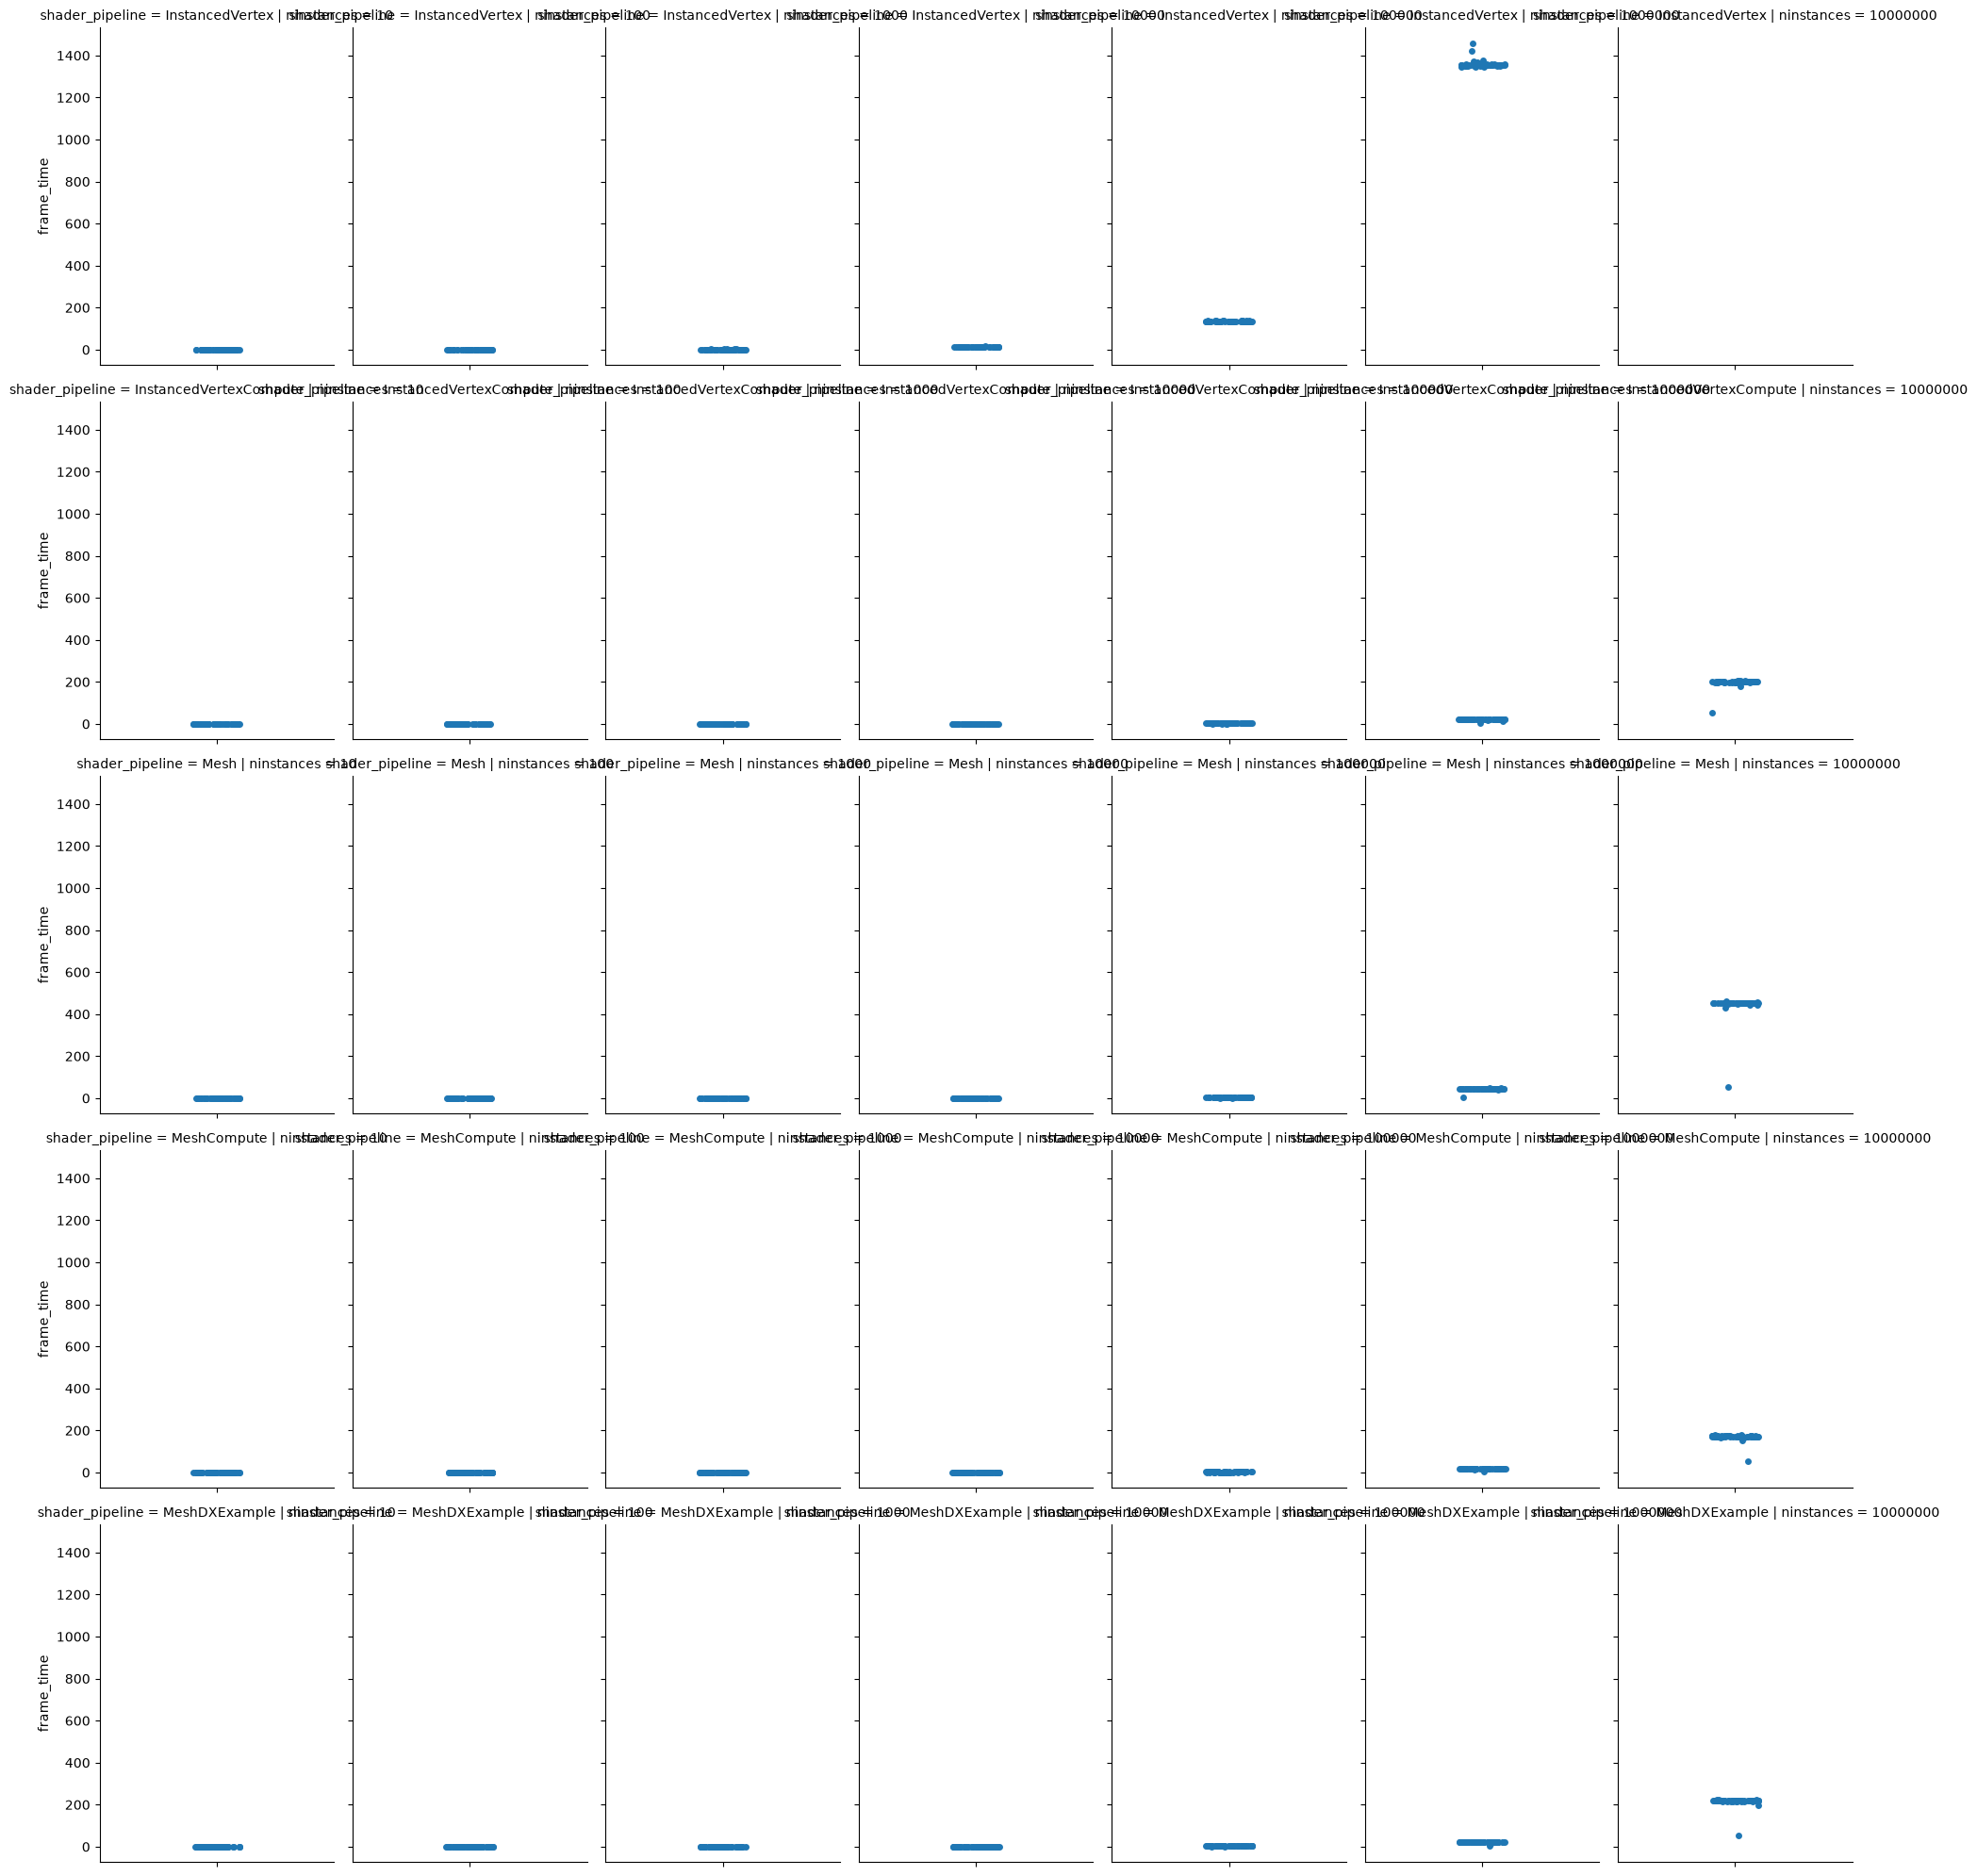

In [18]:
sns.catplot(
    data=frame_df_filtered, y="frame_time", col="ninstances", row="shader_pipeline",
    kind="strip", height=4, aspect=.7,
)

Some more outliers present - these are all on frame 2 but lets prove it by doing the same process again.

In [19]:
frame_df_proc_second_pass = pd.concat(
    [
        frame_df_filtered.set_index(["shader_pipeline", "ninstances"]), 
        frame_df_filtered.groupby(["shader_pipeline", "ninstances"]).std().rename(columns={"frame_time": "std"}).drop("frame_number", axis=1),
        frame_df_filtered.groupby(["shader_pipeline", "ninstances"]).mean().rename(columns={"frame_time": "mean"}).drop("frame_number", axis=1)
    ], 
    axis=1
).reset_index()
frame_df_proc_second_pass["z"] = (frame_df_proc_second_pass["frame_time"] - frame_df_proc_second_pass["mean"]) / frame_df_proc_second_pass["std"]
frame_df_proc_second_pass.head()

,shader_pipeline,ninstances,frame_number,frame_time,std,mean,z
0,InstancedVertex,10,2,0.715,0.117885,0.348966,3.105025
1,InstancedVertex,10,3,0.720,0.117885,0.348966,3.147439
2,InstancedVertex,10,4,0.757,0.117885,0.348966,3.461305
3,InstancedVertex,10,5,0.378,0.117885,0.348966,0.246296
4,InstancedVertex,10,6,0.287,0.117885,0.348966,-0.525646


<Axes: ylabel='z'>

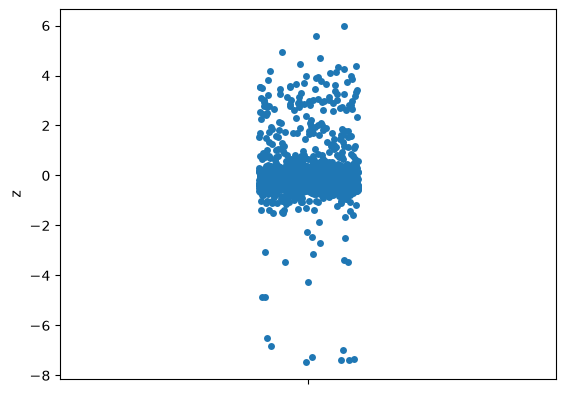

In [20]:
sns.stripplot(frame_df_proc_second_pass, y="z")

<Axes: xlabel='frame_number', ylabel='z'>

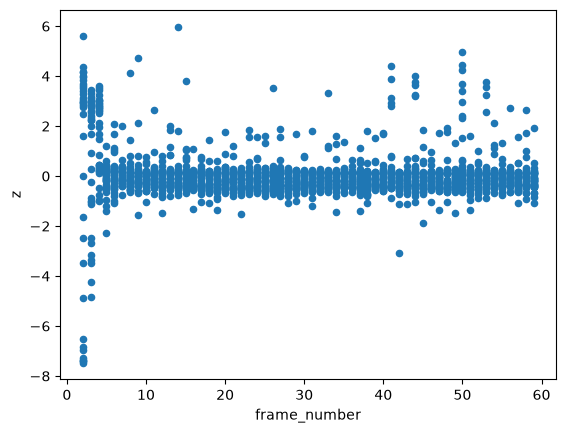

In [21]:
frame_df_proc_second_pass.plot(kind="scatter", x="frame_number", y="z")

Large number of outliers remain at the beginning (frame < 4). Lets just consider frame > 3.

In [22]:
frame_df_filtered = frame_df[frame_df["frame_number"] > 3]

### Distributions

In [29]:
frame_df_filtered.head()

,shader_pipeline,ninstances,frame_number,frame_time
4,InstancedVertex,10,4,0.757
5,InstancedVertex,10,5,0.378
6,InstancedVertex,10,6,0.287
7,InstancedVertex,10,7,0.426
8,InstancedVertex,10,8,0.348


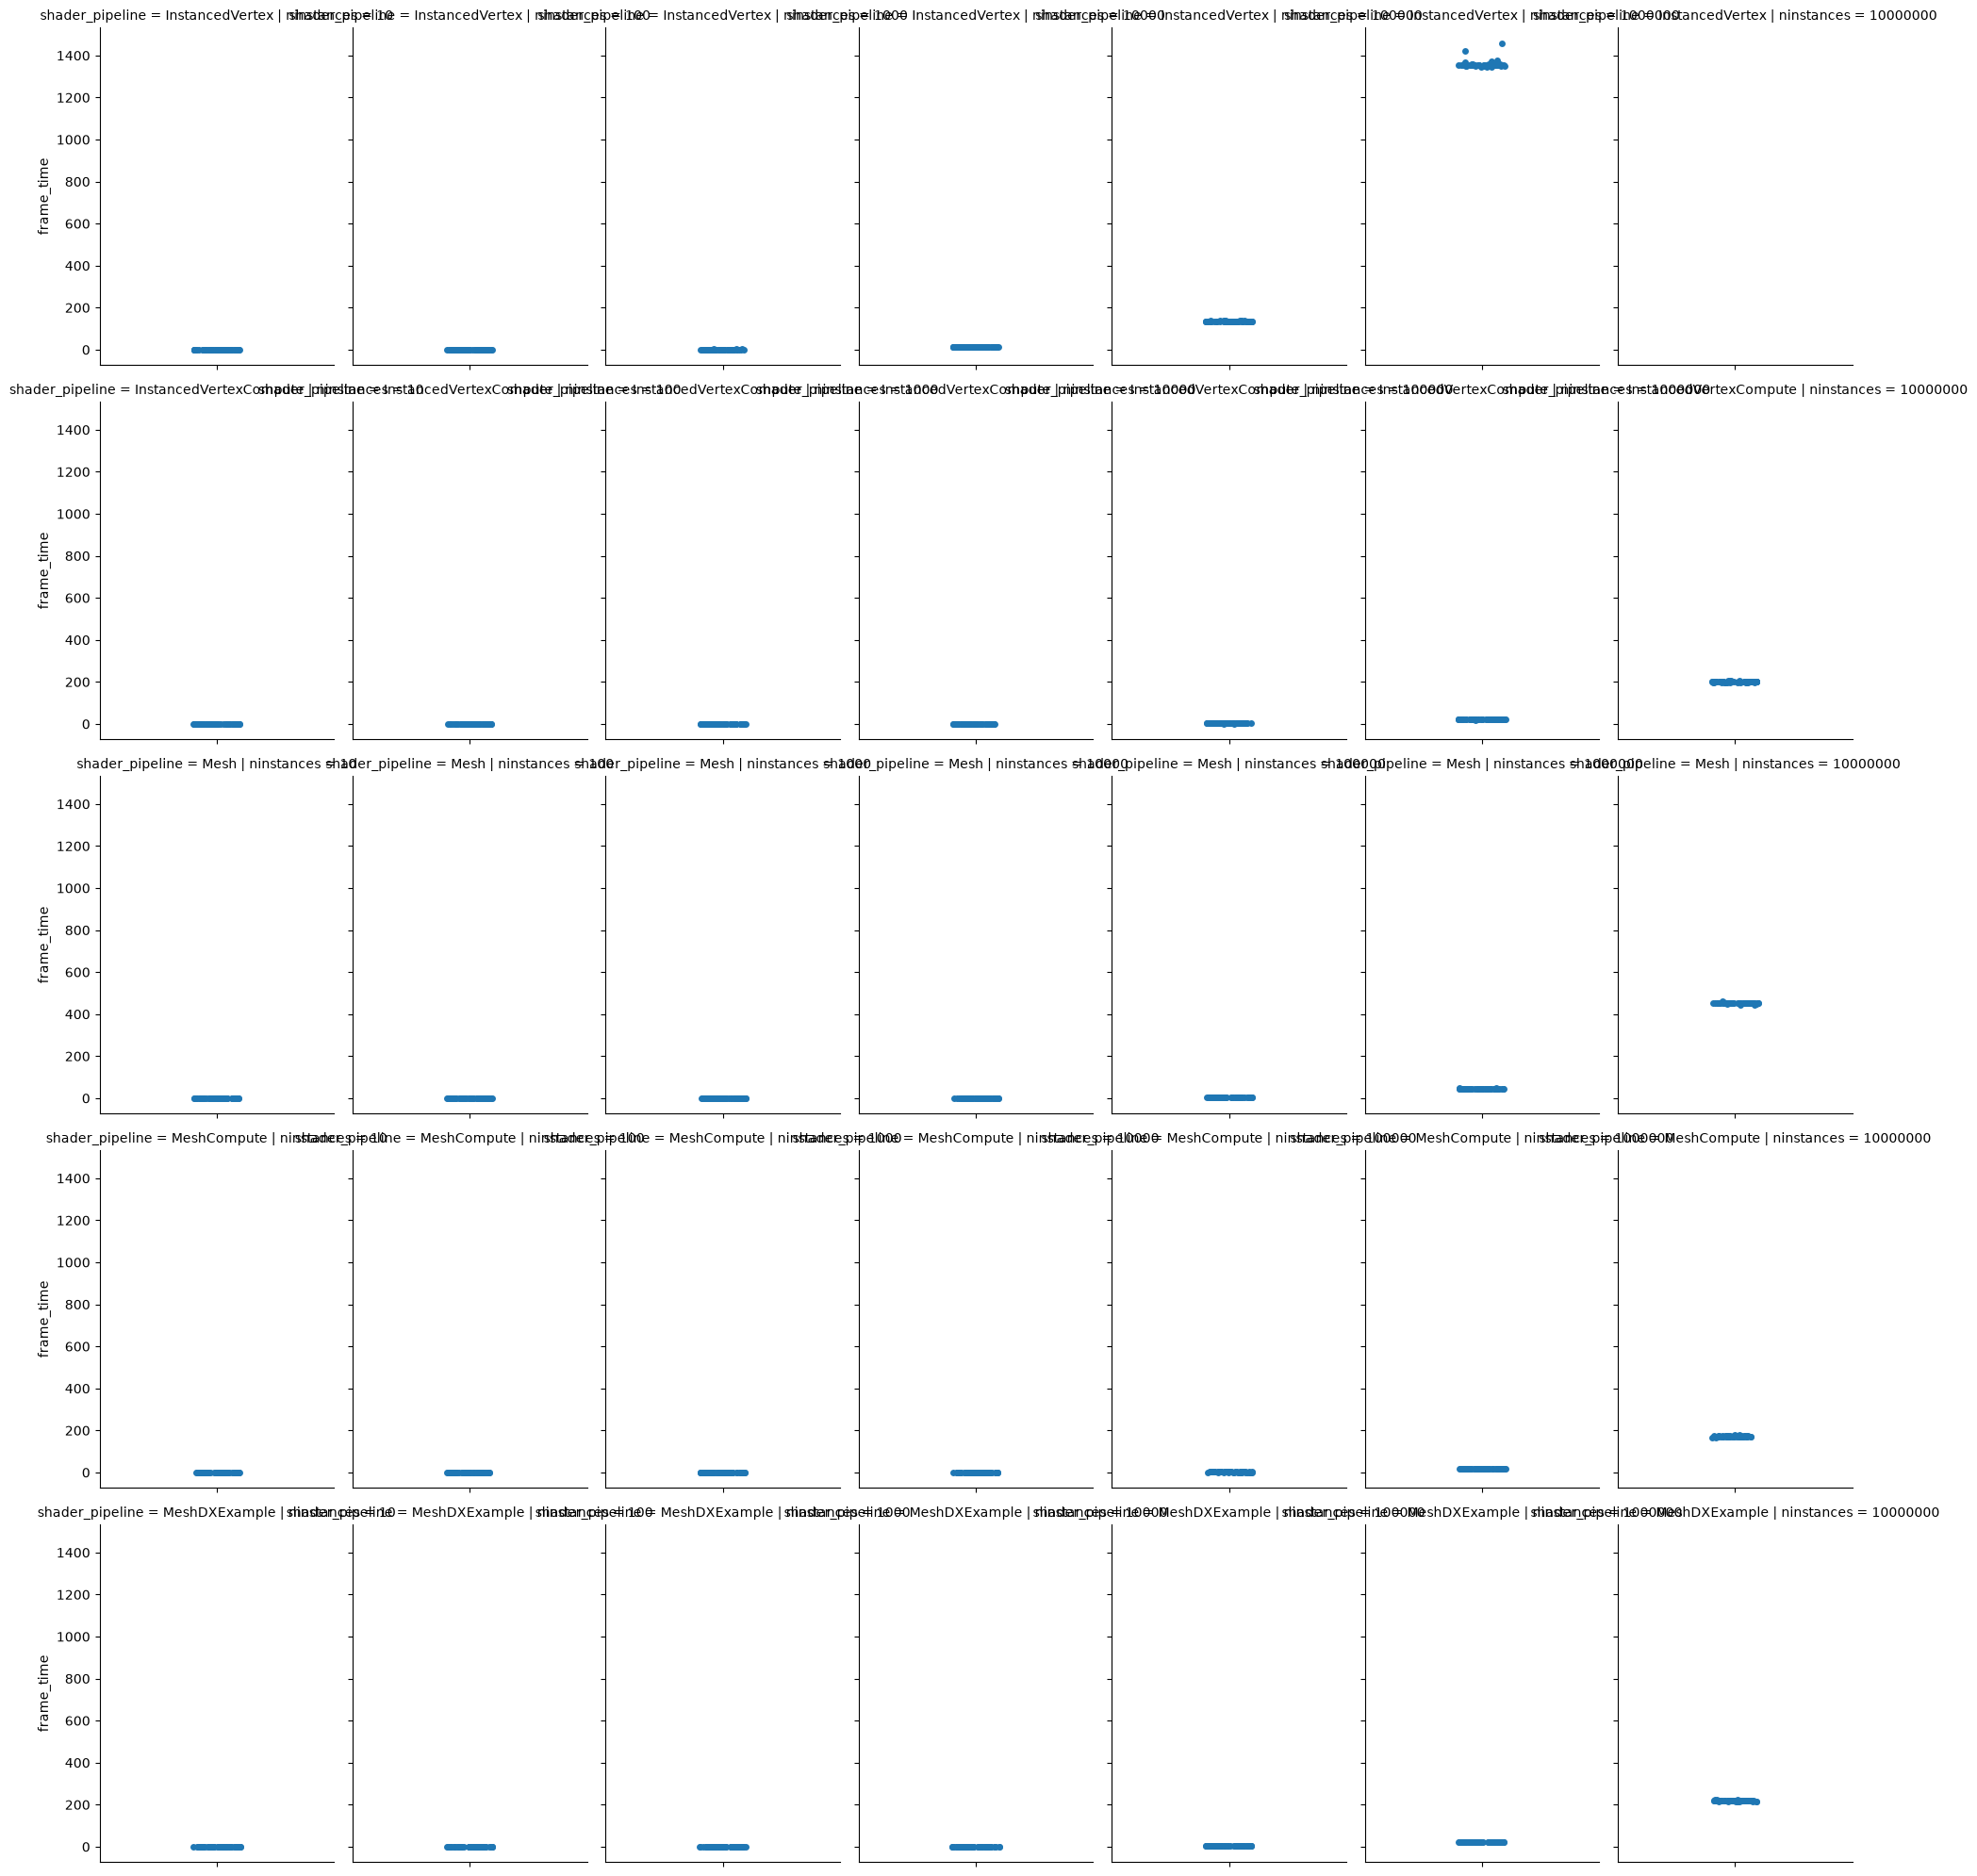

In [179]:
sns.catplot(
    data=frame_df_filtered, y="frame_time", col="ninstances", row="shader_pipeline",
    kind="strip", height=4, aspect=.7,
)

In [32]:
save_dir = Path("../data/figures/app_frame_time/distributions")
try:
    save_dir.mkdir(parents=True)
except FileExistsError as e:
    print("Directory exists, ignoring")
for (shaderpipeline, ninstances), group in frame_df_filtered.groupby(["shader_pipeline", "ninstances"]):
    save_path = save_dir / f"{shaderpipeline}_{ninstances}.png"
    s = group["frame_time"]
    s_median = s.median()
    fig, ax = plt.subplots()

    ax.hist(s, bins=30)
    ax.axvline(s_median, linestyle="--", linewidth=2, label=f"Median = {s_median:.2f}", color="black")
    fig.suptitle("Distribution of App Frame Times", fontsize=14)
    ax.set_title(f"Shader pipeline: {shaderpipeline}; N Instances: {ninstances:.0e}", fontsize=10)
    ax.set_xlabel("Frame Time (ms)")
    ax.set_ylabel("Frequency")
    ax.legend()

    print(f"Saving {str(save_path)}")
    # plt.show()
    plt.savefig(save_path)
    plt.close()

Directory exists, ignoring
Saving ../data/figures/app_frame_time/distributions/InstancedVertex_10.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertex_100.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertex_1000.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertex_10000.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertex_100000.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertex_1000000.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertexCompute_10.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertexCompute_100.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertexCompute_1000.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertexCompute_10000.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertexCompute_100000.png
Saving ../data/figures/app_frame_time/distributions/InstancedVertexCompute_1000000.png
S

### Line charts

In [34]:
frame_stats = (
    frame_df_filtered
        .drop(columns=["frame_number"])
        .groupby(["shader_pipeline", "ninstances"])
        .agg(["median", lambda s: s.quantile(0.025), lambda s: s.quantile(0.975)])
        .rename(columns={
            "<lambda_0>": "low",
            "<lambda_1>": "high",
        })
        .round(2)
        .reset_index()
)

In [35]:
save_dir = Path("../data/figures/app_frame_time/line_charts")
save_dir.mkdir(parents=True, exist_ok=True)

for shaderpipeline, group in frame_stats.groupby("shader_pipeline"):
    save_path = save_dir / f"{shaderpipeline}.png"

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_xscale("log")
    ax.set_yscale("log")

    x = group["ninstances"]
    y = group[("frame_time", "median")]
    low = group[("frame_time", "low")]
    high = group[("frame_time", "high")]

    yerr = [
        y - low,
        high - y,
    ]

    ax.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=2,
        label=shaderpipeline,
        markersize=2,
        linewidth=1,
    )

    ax.set_title("Median Frame Times vs. N Instances per Shader Pipeline")
    ax.set_xlabel("N Instances")
    ax.set_ylabel("Frame Time (ms)")
    ax.legend(title="Shader Pipeline")
    ax.grid(alpha=0.3)

    print(f"Saving {save_path}")
    plt.savefig(save_path)
    plt.close()

Saving ../data/figures/app_frame_time/line_charts/InstancedVertex.png
Saving ../data/figures/app_frame_time/line_charts/InstancedVertexCompute.png
Saving ../data/figures/app_frame_time/line_charts/Mesh.png
Saving ../data/figures/app_frame_time/line_charts/MeshCompute.png
Saving ../data/figures/app_frame_time/line_charts/MeshDXExample.png


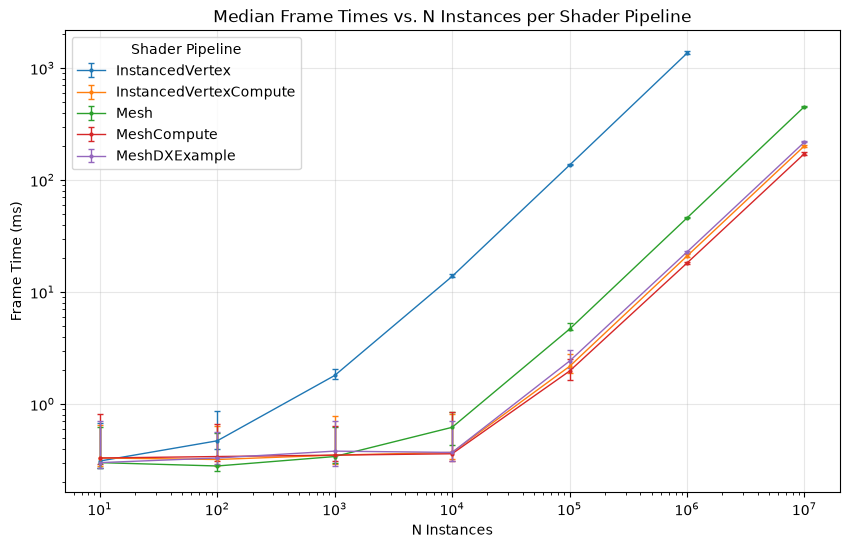

In [36]:
save_dir = Path("../data/figures/app_frame_time/line_charts")
save_dir.mkdir(parents=True, exist_ok=True)

save_filepath = save_dir / "vs_N_Instances_by_pipeline.png"

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xscale("log")
ax.set_yscale("log")

for shaderpipeline, group in frame_stats.groupby("shader_pipeline"):
    x = group["ninstances"]
    y = group[("frame_time", "median")]
    low = group[("frame_time", "low")]
    high = group[("frame_time", "high")]

    yerr = [
        y - low,
        high - y,
    ]

    ax.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=2,
        label=shaderpipeline,
        markersize=2,
        linewidth=1,
    )

ax.set_title("Median Frame Times vs. N Instances per Shader Pipeline")
ax.set_xlabel("N Instances")
ax.set_ylabel("Frame Time (ms)")
ax.legend(title="Shader Pipeline")
ax.grid(alpha=0.3)

plt.savefig(save_filepath)
plt.show()

## GPU Frame time

In [237]:
gpu_frame_df = pd.concat([frame_df_filtered, data_df["gpu_frame_time_ms"]], axis=1, join="inner")

In [241]:
gpu_frame_df["diff"] = gpu_frame_df["frame_time"] - gpu_frame_df["gpu_frame_time_ms"]

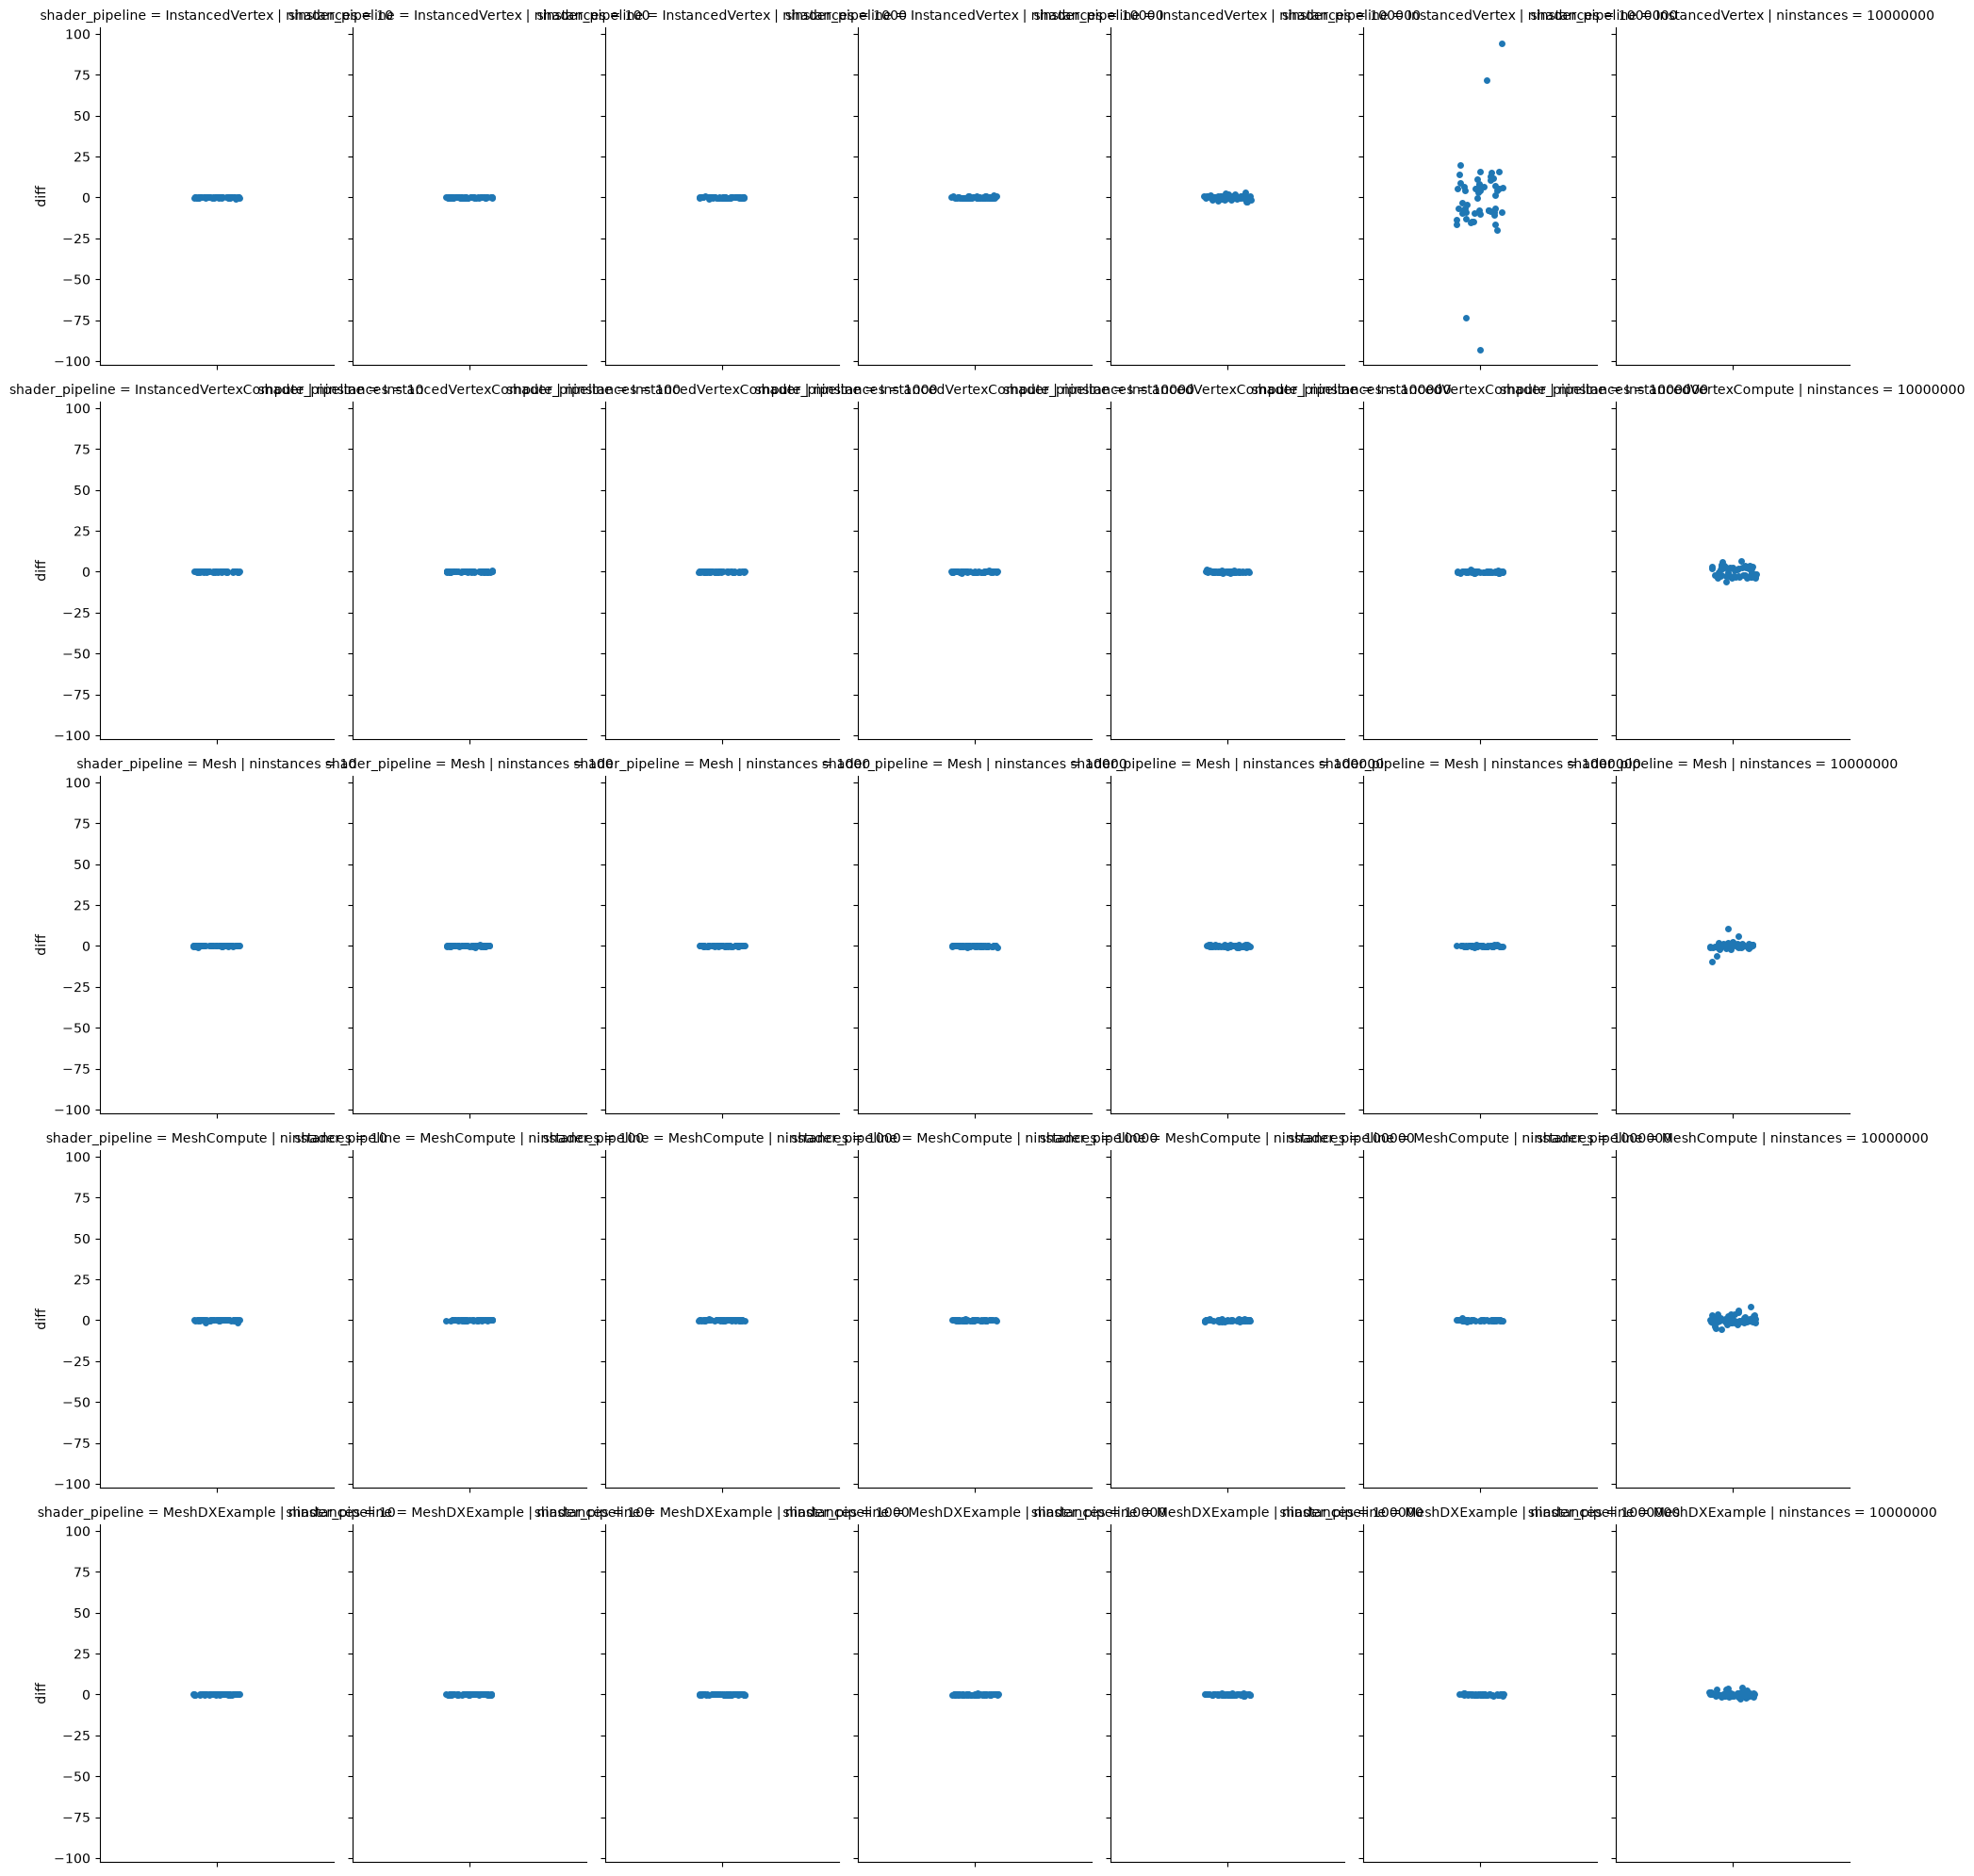

In [242]:
sns.catplot(
    data=gpu_frame_df, y="diff", col="ninstances", row="shader_pipeline",
    kind="strip", height=4, aspect=.7,
)

This data doesn't correlate very well. I should say that it was hard to correlate GPU + CPU frame time contributions to the overall app frame time and was not trivial to extract this from NSys and NGFX. Overall app frame time better.

## VRAM Pressure

In [61]:
vram_df = data_df.set_index(index_cols)["vram_used"].reset_index()

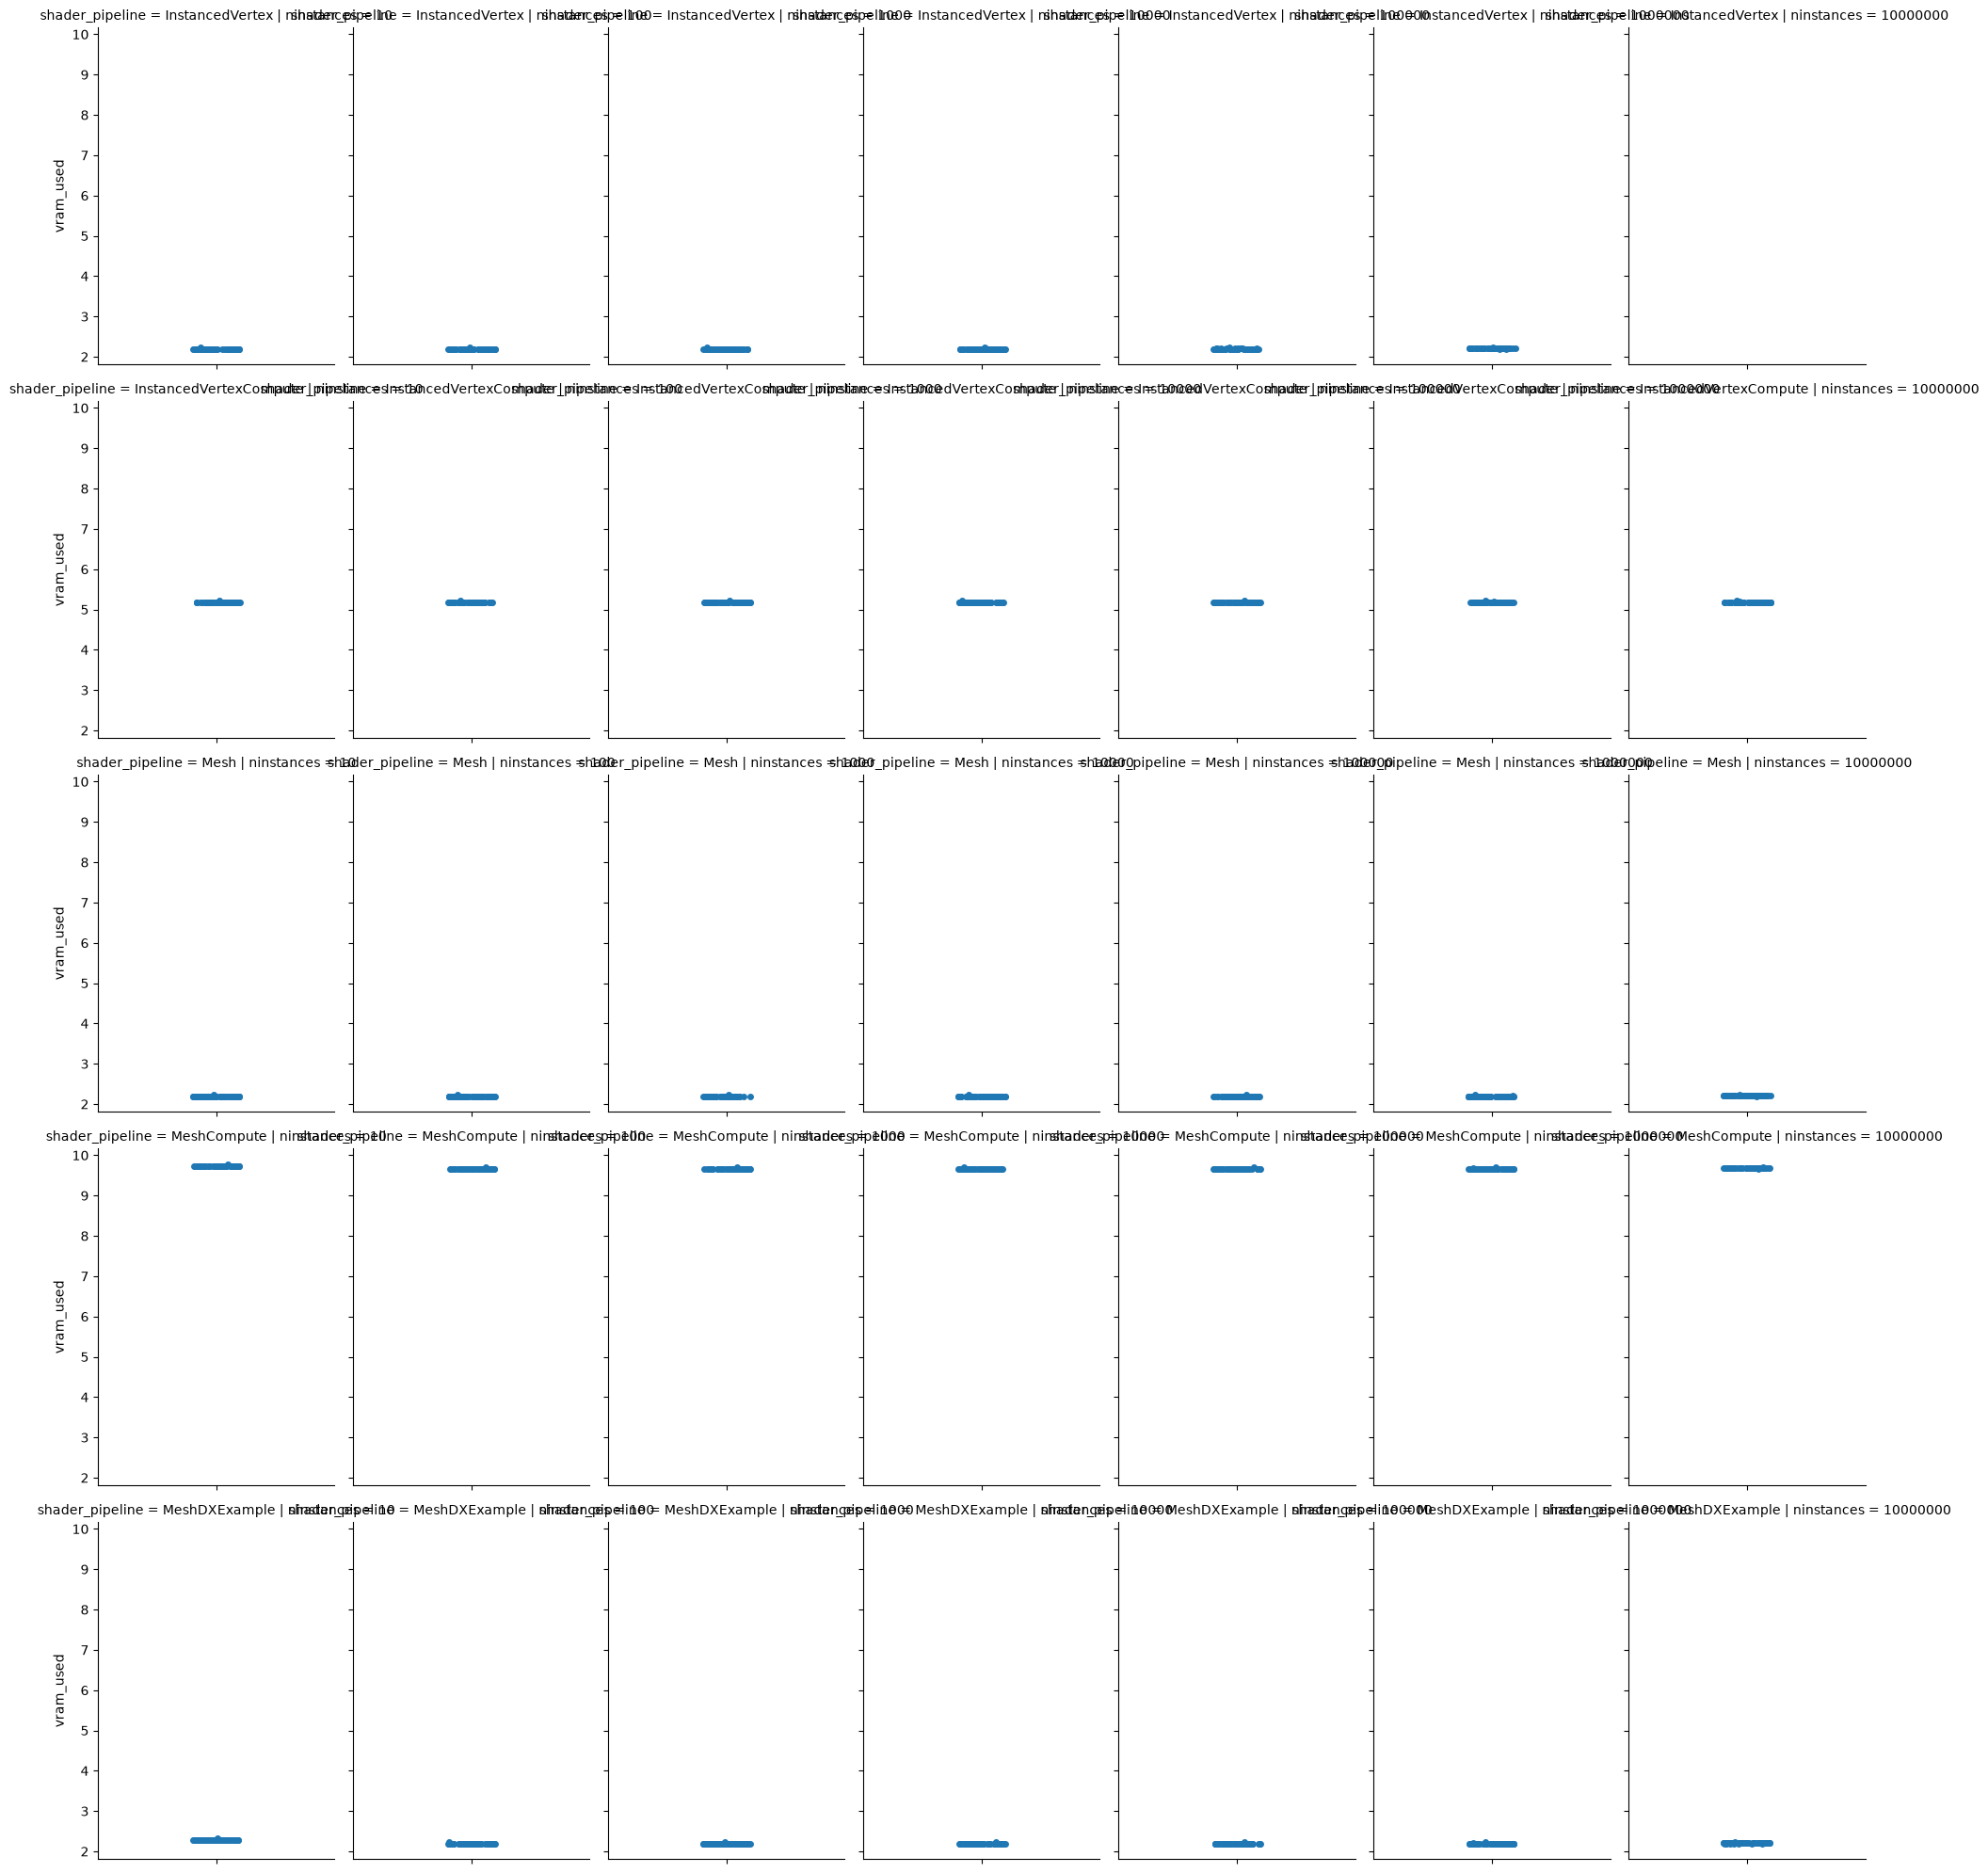

In [62]:
sns.catplot(
    data=vram_df, y="vram_used", col="ninstances", row="shader_pipeline",
    kind="strip", height=4, aspect=.7,
)

In [63]:
vram_stats = (
    vram_df
        .drop(columns=["frame_number", "ninstances"])
        .groupby(["shader_pipeline"])
        .agg(["median", lambda s: s.quantile(0.025), lambda s: s.quantile(0.975)])
        .rename(columns={
            "<lambda_0>": "low",
            "<lambda_1>": "high",
        })
        .round(2)
        .reset_index()
        .sort_values(("vram_used", "median"))
)

In [65]:
Path("../data/tables/").mkdir()
vram_stats.to_csv(Path("../data/tables/vram_stats.csv"))

In [43]:
vram_stats["shader_pipeline"]

0           InstancedVertex
2                      Mesh
4             MeshDXExample
1    InstancedVertexCompute
3               MeshCompute
Name: shader_pipeline, dtype: str

Directory exists, ignoring


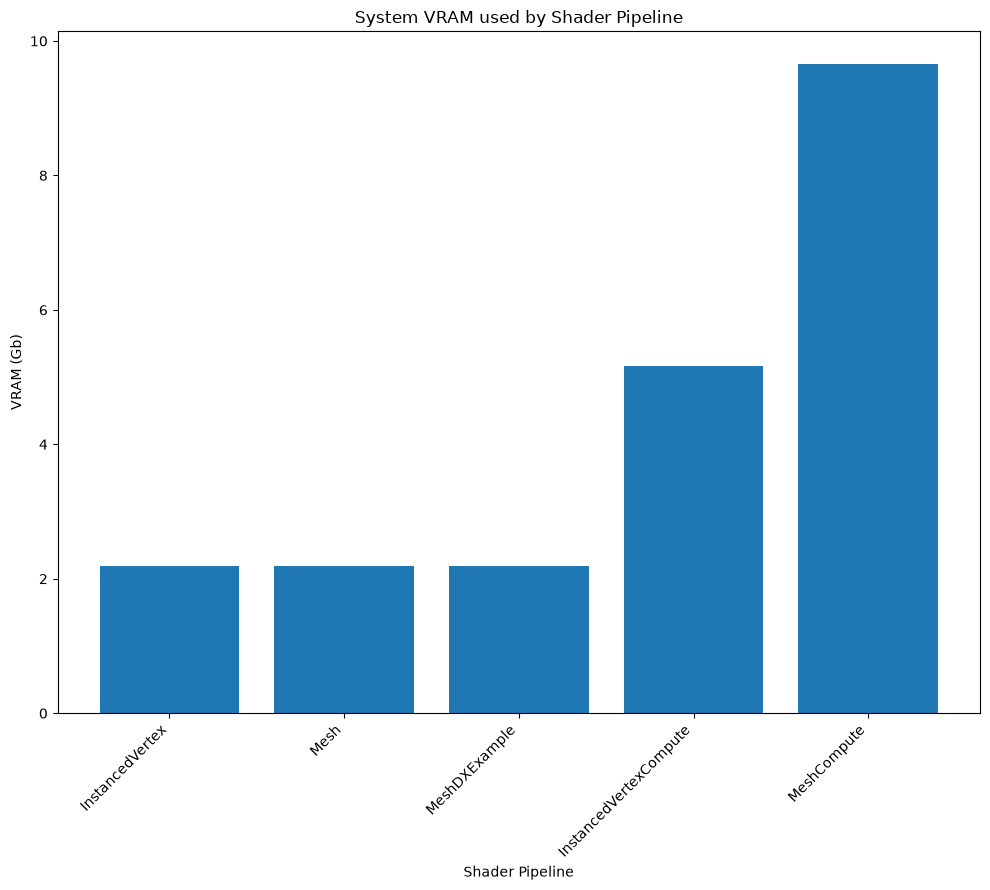

In [44]:
save_dir = Path("../data/figures/vram")
try:
    save_dir.mkdir(parents=True)
except FileExistsError as e:
    print("Directory exists, ignoring")
save_filepath = save_dir/"vram_used_by_pipeline.png"

fig, ax = plt.subplots(figsize=(10, 9))

ax.bar(vram_stats["shader_pipeline"], vram_stats[("vram_used", "median")])

ax.set_title("System VRAM used by Shader Pipeline")
ax.set_xlabel("Shader Pipeline")
ax.set_ylabel("VRAM (Gb)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(save_filepath)
plt.show()

VRAM expected to be static as buffer allocation isn't dynamic so any variation is likely due to changes in system VRAM used during the experiment.

## GPU Command Data

In [51]:
gpu_command_df["command_proc"] = gpu_command_df["command"].apply(lambda s: s.split('(')[0])

In [52]:
gpu_command_df_proc = gpu_command_df.drop_duplicates(subset=["shader_pipeline", "ninstances", "frame_number", "event_number", "command_proc"])
gpu_command_df_proc = gpu_command_df_proc.fillna(0.0)

In [53]:
gpu_command_df_proc = pd.concat(
    [
        gpu_command_df_proc.set_index(["shader_pipeline", "ninstances", "frame_number"]),
        gpu_command_df_proc.groupby(["shader_pipeline", "ninstances", "frame_number"]).sum()[["gpu_time_ms"]]
        .rename({"gpu_time_ms": "total_gpu_frame_time_ms"}, axis=1)
    ],
    axis=1,
).reset_index()

In [54]:
gpu_command_df_proc["frame_percent_total"] = gpu_command_df_proc["gpu_time_ms"] / gpu_command_df_proc["total_gpu_frame_time_ms"]

### Boxplots

In [66]:
save_dir = Path("../data/figures/vulkan_command_time/distributions")
try:
    save_dir.mkdir(parents=True)
except FileExistsError as e:
    print("Directory exists, ignoring")
sns.set_context("notebook", font_scale=1.5)
for (shaderpipeline, ninstances), group in gpu_command_df_proc.groupby(
    ["shader_pipeline", "ninstances"]
):
    save_path = save_dir / f"{shaderpipeline}_{ninstances}.png"
    grid = sns.catplot(group, x="command_proc", y="gpu_time_ms", kind="box", height=9, aspect=10/9)
    plt.xticks(rotation=45, ha="right")
    plt.suptitle("Boxplot Distribution of NGFX GPU Times by Vulkan Command")
    grid.ax.set_title(f"Shader Pipeline: {shaderpipeline}; N Instances: {ninstances:.0e}")
    grid.ax.set_xlabel("Vulkan Command")
    grid.ax.set_ylabel("GPU Time (ms)")

    plt.tight_layout()

    print(save_path)
    plt.savefig(save_path)
    plt.close()
    # plt.show()
    # break

Directory exists, ignoring
../data/figures/vulkan_command_time/distributions/InstancedVertex_10.png
../data/figures/vulkan_command_time/distributions/InstancedVertex_100.png
../data/figures/vulkan_command_time/distributions/InstancedVertex_1000.png
../data/figures/vulkan_command_time/distributions/InstancedVertex_10000.png
../data/figures/vulkan_command_time/distributions/InstancedVertex_100000.png
../data/figures/vulkan_command_time/distributions/InstancedVertex_1000000.png
../data/figures/vulkan_command_time/distributions/InstancedVertexCompute_10.png
../data/figures/vulkan_command_time/distributions/InstancedVertexCompute_100.png
../data/figures/vulkan_command_time/distributions/InstancedVertexCompute_1000.png
../data/figures/vulkan_command_time/distributions/InstancedVertexCompute_10000.png
../data/figures/vulkan_command_time/distributions/InstancedVertexCompute_100000.png
../data/figures/vulkan_command_time/distributions/InstancedVertexCompute_1000000.png
../data/figures/vulkan_co

### Column charts

In [63]:
save_dir = Path("../data/figures/vulkan_command_time/column_percent_share")
try:
    save_dir.mkdir(parents=True)
except FileExistsError as e:
    print("Directory exists, ignoring")

for (shaderpipeline, ninstances), group in gpu_command_df_proc.groupby(
    ["shader_pipeline", "ninstances"]
):
    save_path = save_dir / f"{shaderpipeline}_{ninstances}.png"
    group_stats = group.groupby("command_proc")["gpu_time_ms"].median() / group.groupby("command_proc")["gpu_time_ms"].median().sum()
    ax = group_stats.sort_values().plot(kind="bar", figsize=(10,9))
    plt.xticks(rotation=45, ha="right")
    plt.suptitle("Boxplot Distribution of NGFX GPU Times by Vulkan Command")
    ax.set_title(f"Shader Pipeline: {shaderpipeline}; N Instances: {ninstances:.0e}")
    ax.set_xlabel("Vulkan Command")
    ax.set_ylabel("Average Fraction of GPU Time")
    ax.set_ylim(0.0, 1.0)

    plt.tight_layout()

    print(save_path)
    plt.savefig(save_path)
    plt.close()
    # plt.show()
    # break

Directory exists, ignoring
../data/figures/vulkan_command_time/column_percent_share/InstancedVertex_10.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertex_100.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertex_1000.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertex_10000.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertex_100000.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertex_1000000.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertexCompute_10.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertexCompute_100.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertexCompute_1000.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertexCompute_10000.png
../data/figures/vulkan_command_time/column_percent_share/InstancedVertexCompute_100000.png
../data/figures/vulkan_command_ti

In [64]:
gpu_command_group_stats = gpu_command_df_proc.groupby(["shader_pipeline", "command_proc"])["gpu_time_ms"].median().reset_index()
gpu_command_group_stats = (
    gpu_command_group_stats
    .set_index("shader_pipeline")
    .join(
        gpu_command_group_stats
        .groupby("shader_pipeline")["gpu_time_ms"]
        .sum()
        .rename("total")
    )
)
gpu_command_group_stats["frac_total"] = gpu_command_group_stats["gpu_time_ms"] / gpu_command_group_stats["total"]
gpu_command_group_stats = gpu_command_group_stats.reset_index()

In [67]:
save_dir = Path("../data/figures/vulkan_command_time/average_column_percent_share")
try:
    save_dir.mkdir(parents=True)
except FileExistsError as e:
    print("Directory exists, ignoring")

for shaderpipeline, group in gpu_command_group_stats.groupby("shader_pipeline"):
    save_path = save_dir / f"{shaderpipeline}.png"

    # fig, ax = plt.subplots(figsize=(10, 6))
    
    fracs = group.set_index("command_proc")["frac_total"]
    ax = fracs.sort_values().plot(kind="bar", figsize=(10, 9))
    plt.xticks(rotation=45, ha="right")
    plt.suptitle("Fraction of NGFX GPU Times\nAcross all Frames by Vulkan Command")
    ax.set_title(f"Shader Pipeline: {shaderpipeline}")
    ax.set_xlabel("Vulkan Command")
    ax.set_ylabel("Average Fraction of GPU Time")
    ax.set_ylim(0.0, 1.0)
    plt.tight_layout()
    
    print(save_path)
    plt.savefig(save_path)
    plt.close()
    

Directory exists, ignoring
../data/figures/vulkan_command_time/average_column_percent_share/InstancedVertex.png
../data/figures/vulkan_command_time/average_column_percent_share/InstancedVertexCompute.png
../data/figures/vulkan_command_time/average_column_percent_share/Mesh.png
../data/figures/vulkan_command_time/average_column_percent_share/MeshCompute.png
../data/figures/vulkan_command_time/average_column_percent_share/MeshDXExample.png


# Statistical Analysis

Some AI help in putting this general script together to follow process from Research Methods

In [42]:
shapiro_results = []
test_results = []
posthoc_results = []


for ninstances, ninstances_df in frame_df_filtered.groupby("ninstances"):

    groups = {
        shader_pipeline: group["frame_time"].dropna()
        for shader_pipeline, group
        in ninstances_df.groupby("shader_pipeline")
    }

    # normality test
    normality_by_group = {}

    for shader_pipeline, values in groups.items():
        statistic, p_value = shapiro(values)

        shapiro_results.append({
            "ninstances": ninstances,
            "shader_pipeline": shader_pipeline,
            "n": len(values),
            "median": values.median(),
            "shapiro_statistic": statistic,
            "shapiro_p_value": p_value,
            "normal": p_value > 0.05,
        })

        normality_by_group[shader_pipeline] = p_value > 0.05
    all_normal = all(normality_by_group.values())

    # kruskal-wallis (non-normal) or ANOVA (normal)
    if all_normal:
        statistic, p_value = f_oneway(*groups.values())
        test = "ANOVA"
    else:
        statistic, p_value = kruskal(*groups.values())
        test = "Kruskal-Wallis"

    test_results.append({
        "ninstances": ninstances,
        "test": test,
        "statistic": statistic,
        "p_value": p_value,
        "significant": p_value < 0.05,
    })

    # posthoc
    if p_value < 0.05:

        if all_normal:
            # tukey for all normal
            tukey = sp.posthoc_tukey(
                ninstances_df,
                val_col="frame_time",
                group_col="shader_pipeline",
            )

            for pipeline_a in tukey.index:
                for pipeline_b in tukey.columns:

                    if pipeline_a >= pipeline_b:
                        continue

                    p_adjusted = tukey.loc[pipeline_a, pipeline_b]

                    posthoc_results.append({
                        "ninstances": ninstances,
                        "test": "Tukey HSD",
                        "shader_pipeline_a": pipeline_a,
                        "shader_pipeline_b": pipeline_b,
                        "p_value": p_adjusted,
                        "p_value_adjusted": p_adjusted,
                        "significant": p_adjusted < 0.05,
                    })

        else:
            # dunn + bonferroni (spss equivalent) if any non-normal
            dunn = sp.posthoc_dunn(
                ninstances_df,
                val_col="frame_time",
                group_col="shader_pipeline",
                p_adjust="bonferroni",
            )

            for pipeline_a in dunn.index:
                for pipeline_b in dunn.columns:

                    if pipeline_a >= pipeline_b:
                        continue

                    p_adjusted = dunn.loc[pipeline_a, pipeline_b]

                    posthoc_results.append({
                        "ninstances": ninstances,
                        "test": "Dunn",
                        "shader_pipeline_a": pipeline_a,
                        "shader_pipeline_b": pipeline_b,
                        "p_value_adjusted": p_adjusted,
                        "significant": p_adjusted < 0.05,
                    })

shapiro_df = pd.DataFrame(shapiro_results)
test_results_df = pd.DataFrame(test_results)
posthoc_df = pd.DataFrame(posthoc_results)

In [66]:
shapiro_df.to_csv(Path("../data/tables/shapiro_wilks_test.csv"))

They're not all normal so Kruskill-Wallis.

In [44]:
test_results_df

,ninstances,test,statistic,p_value,significant
0,10,Kruskal-Wallis,39.032632,6.859161e-08,True
1,100,Kruskal-Wallis,164.925871,1.283204e-34,True
2,1000,Kruskal-Wallis,146.889291,9.445593e-31,True
3,10000,Kruskal-Wallis,190.467310,4.206067e-40,True
4,100000,Kruskal-Wallis,241.578226,4.241927e-51,True
5,1000000,Kruskal-Wallis,267.827511,9.376724e-57,True
6,10000000,Kruskal-Wallis,209.066778,4.633094e-45,True


In [67]:
test_results_df.to_csv(Path("../data/tables/kruskal_wallis_test.csv"))

All results significant so post-hoc analysis

In [70]:
posthoc_df.to_clipboard()

In [68]:
posthoc_df.to_csv(Path("../data/tables/posthoc_tests.csv"))

In [47]:
posthoc_df[~posthoc_df["significant"]]

,ninstances,test,shader_pipeline_a,shader_pipeline_b,p_value_adjusted,significant
0,10,Dunn,InstancedVertex,InstancedVertexCompute,0.232404,False
1,10,Dunn,InstancedVertex,Mesh,0.806070,False
3,10,Dunn,InstancedVertex,MeshDXExample,0.598391,False
5,10,Dunn,InstancedVertexCompute,MeshCompute,1.000000,False
8,10,Dunn,Mesh,MeshDXExample,1.000000,False
16,100,Dunn,InstancedVertexCompute,MeshDXExample,0.343649,False
19,100,Dunn,MeshCompute,MeshDXExample,1.000000,False
24,1000,Dunn,InstancedVertexCompute,Mesh,1.000000,False
25,1000,Dunn,InstancedVertexCompute,MeshCompute,1.000000,False
26,1000,Dunn,InstancedVertexCompute,MeshDXExample,0.122876,False


AI help for the cld algorithm

In [55]:
def generate_cld(shapiro_df, posthoc_df):
    results = []

    for ninstances, median_df in shapiro_df.groupby("ninstances"):

        median_df = (
            median_df
            .sort_values("median")
            .reset_index(drop=True)
        )

        pipelines = median_df["shader_pipeline"].tolist()

        # -----------------------------------------------------
        # Significant / non-significant matrix
        # -----------------------------------------------------
        significant = {
            (a, b): False
            for a in pipelines
            for b in pipelines
        }

        posthoc = posthoc_df[
            posthoc_df["ninstances"] == ninstances
        ]

        for _, row in posthoc.iterrows():
            a = row["shader_pipeline_a"]
            b = row["shader_pipeline_b"]

            significant[(a, b)] = row["significant"]
            significant[(b, a)] = row["significant"]

        # -----------------------------------------------------
        # Find all non-significant cliques
        # -----------------------------------------------------
        #
        # A letter represents a set of pipelines where every
        # pair is NOT significantly different.
        #
        cliques = []

        for size in range(len(pipelines), 0, -1):

            for combination in combinations(pipelines, size):

                if all(
                    not significant[(a, b)]
                    for a, b in combinations(combination, 2)
                ):
                    cliques.append(set(combination))

        # Remove duplicate/subset cliques
        unique_cliques = []

        for clique in cliques:
            if not any(
                clique < existing
                for existing in unique_cliques
            ):
                unique_cliques.append(clique)

        # -----------------------------------------------------
        # Assign letters
        # -----------------------------------------------------
        pipeline_letters = {
            pipeline: []
            for pipeline in pipelines
        }

        for i, clique in enumerate(unique_cliques):

            if i >= len(ascii_lowercase):
                raise ValueError(
                    "More than 26 CLD groups required."
                )

            letter = ascii_lowercase[i]

            for pipeline in clique:
                pipeline_letters[pipeline].append(letter)

        # -----------------------------------------------------
        # Results
        # -----------------------------------------------------
        for _, row in median_df.iterrows():

            pipeline = row["shader_pipeline"]

            results.append({
                "ninstances": ninstances,
                "shader_pipeline": pipeline,
                "median": row["median"],
                "cld": "".join(
                    pipeline_letters[pipeline]
                ),
            })

    return pd.DataFrame(results)


cld_df = generate_cld(
    shapiro_df,
    posthoc_df,
)

cld_df = (
    cld_df
    .sort_values(["ninstances", "median"])
    .reset_index(drop=True)
)

cld_df["median"] = cld_df["median"].round(3)

In [69]:
cld_df.sort_values(["ninstances", "median", "cld"]).to_csv(Path("../data/tables/cld_table.csv"))

double check this! Looks correct but worth just going through the results when all collated together and making sure it's all consistent